# 07 · Convolutional Neural Networks on MNIST

**Thesis reference:** Chapter 2, Section 2.2 (*Convolutional Neural Nets*): 2D convolution, stride, max-pooling, counting inputs and outputs, softmax outputs, residual networks, and the regularizers dropout and batch normalization.

Contents:
1. 2D convolution by hand, checked against PyTorch.
2. The output-size formula $\left\lfloor \frac{n - k + 2p}{s} \right\rfloor + 1$ for stride $s$ and padding $p$.
3. A small CNN trained on handwritten digits, with an **ablation study**: baseline vs + dropout vs + batch norm vs + residual block.
4. Softmax probabilities, the confusion matrix, and the learned first-layer filters.

Everything runs on a CPU in a few minutes.

In [1]:
import os
import time
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from torch.utils.data import DataLoader, Subset
from torchvision import datasets, transforms

FIG = Path("..") / "figures"
FIG.mkdir(exist_ok=True)
DATA = Path("..") / "data"
plt.rcParams.update({"figure.dpi": 110})
torch.manual_seed(0)
torch.set_num_threads(os.cpu_count() or 1)
print("PyTorch", torch.__version__)

PyTorch 2.14.1+cpu


In [2]:
tfm = transforms.Compose([transforms.ToTensor(), transforms.Normalize((0.1307,), (0.3081,))])
train_full = datasets.MNIST(DATA, train=True, download=True, transform=tfm)
test_set = datasets.MNIST(DATA, train=False, download=True, transform=tfm)
train_set = Subset(train_full, torch.randperm(len(train_full), generator=torch.Generator().manual_seed(0))[:20_000].tolist())
print(f"training on {len(train_set)} of {len(train_full)} images, testing on {len(test_set)}")

0.3%

0.7%

1.0%

1.3%

1.7%

...

97.4%

99.4%

100.0%

100.0%

training on 20000 of 60000 images, testing on 10000


## 1. Convolution by hand

Deep-learning "convolution" slides a small filter $K$ over the image and takes dot products (strictly speaking, a cross-correlation):
$$Y[i,j] = \sum_{u,v} K[u,v]\; X[i+u,\, j+v].$$
Below, Sobel filters detect vertical and horizontal edges in a digit.

max |NumPy - PyTorch| = 1.341104507446289e-06


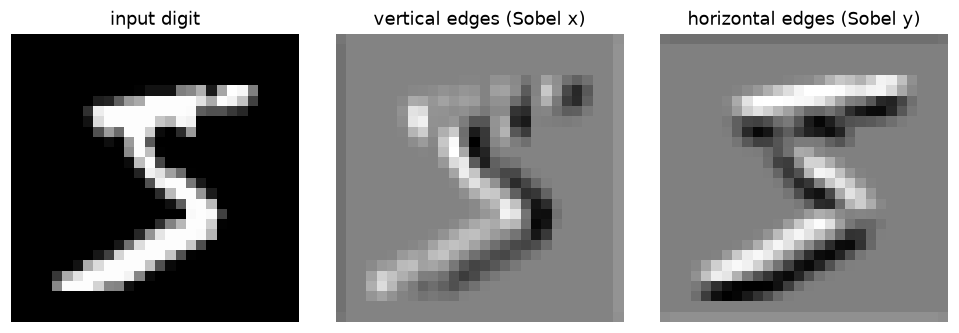

In [3]:
def conv2d_numpy(X, K, stride=1, pad=0):
    X = np.pad(X, pad)
    k = K.shape[0]
    out = (X.shape[0] - k) // stride + 1
    Y = np.empty((out, out))
    for i in range(out):
        for j in range(out):
            Y[i, j] = np.sum(K * X[i * stride:i * stride + k, j * stride:j * stride + k])
    return Y

img = train_full[0][0][0].numpy()
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], float)
sobel_y = sobel_x.T
edges_x = conv2d_numpy(img, sobel_x, pad=1)
edges_y = conv2d_numpy(img, sobel_y, pad=1)

torch_out = F.conv2d(torch.tensor(img)[None, None], torch.tensor(sobel_x)[None, None].float(), padding=1)[0, 0].numpy()
print("max |NumPy - PyTorch| =", np.abs(edges_x - torch_out).max())

fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, (im, t) in zip(axes, [(img, "input digit"), (edges_x, "vertical edges (Sobel x)"), (edges_y, "horizontal edges (Sobel y)")]):
    ax.imshow(im, cmap="gray"); ax.set_title(t); ax.axis("off")
plt.tight_layout()
plt.show()

## 2. Counting outputs: stride and padding
For an $n\times n$ input, a $k\times k$ filter, stride $s$ and padding $p$, the output is $m \times m$ with $m = \lfloor (n - k + 2p)/s \rfloor + 1$.

In [4]:
x = torch.zeros(1, 1, 28, 28)
print(f"{'k':>2s} {'s':>2s} {'p':>2s} {'formula':>8s} {'PyTorch':>8s}")
for k, s, p in [(3, 1, 0), (3, 1, 1), (5, 2, 1), (5, 2, 2), (7, 3, 0)]:
    formula = (28 - k + 2 * p) // s + 1
    actual = nn.Conv2d(1, 1, k, stride=s, padding=p)(x).shape[-1]
    print(f"{k:2d} {s:2d} {p:2d} {formula:8d} {actual:8d}")

 k  s  p  formula  PyTorch
 3  1  0       26       26
 3  1  1       28       28
 5  2  1       13       13
 5  2  2       14       14
 7  3  0        8        8


## 3. The network and the ablation study

```
conv 3x3 (1→16) → [BN] → ReLU → max-pool 2      28×28 → 14×14
[residual block: conv–[BN]–ReLU–conv–[BN] + skip → ReLU]
conv 3x3 (16→32) → [BN] → ReLU → max-pool 2     14×14 → 7×7
flatten → [dropout] → linear 1568→64 → ReLU → [dropout] → linear 64→10 → softmax
```
Brackets mark the optional components we switch on one at a time.

In [5]:
class ResidualBlock(nn.Module):
    def __init__(self, ch, bn):
        super().__init__()
        self.c1, self.c2 = nn.Conv2d(ch, ch, 3, padding=1), nn.Conv2d(ch, ch, 3, padding=1)
        self.b1 = nn.BatchNorm2d(ch) if bn else nn.Identity()
        self.b2 = nn.BatchNorm2d(ch) if bn else nn.Identity()

    def forward(self, x):
        return F.relu(x + self.b2(self.c2(F.relu(self.b1(self.c1(x))))))   # F(x) + x


class SmallCNN(nn.Module):
    def __init__(self, dropout=0.0, bn=False, residual=False):
        super().__init__()
        self.conv1, self.conv2 = nn.Conv2d(1, 16, 3, padding=1), nn.Conv2d(16, 32, 3, padding=1)
        self.bn1 = nn.BatchNorm2d(16) if bn else nn.Identity()
        self.bn2 = nn.BatchNorm2d(32) if bn else nn.Identity()
        self.res = ResidualBlock(16, bn) if residual else nn.Identity()
        self.drop = nn.Dropout(dropout)
        self.fc1, self.fc2 = nn.Linear(32 * 7 * 7, 64), nn.Linear(64, 10)

    def forward(self, x):
        x = F.max_pool2d(F.relu(self.bn1(self.conv1(x))), 2)
        x = self.res(x)
        x = F.max_pool2d(F.relu(self.bn2(self.conv2(x))), 2)
        x = self.drop(torch.flatten(x, 1))
        return self.fc2(self.drop(F.relu(self.fc1(x))))   # logits; softmax lives in the loss


def evaluate(model, loader):
    model.eval()
    correct, loss_sum = 0, 0.0
    with torch.no_grad():
        for xb, yb in loader:
            out = model(xb)
            loss_sum += F.cross_entropy(out, yb, reduction="sum").item()
            correct += (out.argmax(1) == yb).sum().item()
    return loss_sum / len(loader.dataset), correct / len(loader.dataset)


def train(model, epochs=4, lr=1e-3, seed=0):
    torch.manual_seed(seed)
    train_loader = DataLoader(train_set, batch_size=128, shuffle=True, generator=torch.Generator().manual_seed(seed))
    test_loader = DataLoader(test_set, batch_size=1000)
    opt = torch.optim.Adam(model.parameters(), lr=lr)
    hist = {"train_loss": [], "test_loss": [], "test_acc": []}
    for _ in range(epochs):
        model.train()
        running = 0.0
        for xb, yb in train_loader:
            opt.zero_grad()
            loss = F.cross_entropy(model(xb), yb)
            loss.backward()
            opt.step()
            running += loss.item() * len(xb)
        hist["train_loss"].append(running / len(train_set))
        tl, ta = evaluate(model, test_loader)
        hist["test_loss"].append(tl)
        hist["test_acc"].append(ta)
    return hist

In [6]:
variants = {
    "baseline":            dict(),
    "+ dropout (0.3)":     dict(dropout=0.3),
    "+ batch norm":        dict(bn=True),
    "+ BN + residual":     dict(bn=True, residual=True),
}
models, histories = {}, {}
for name, cfg in variants.items():
    torch.manual_seed(0)
    model = SmallCNN(**cfg)
    t0 = time.time()
    histories[name] = train(model)
    models[name] = model
    n_params = sum(p.numel() for p in model.parameters())
    print(f"{name:18s} params {n_params:7,d}   test acc {histories[name]['test_acc'][-1]:.4f}   ({time.time() - t0:.0f}s)")

baseline           params 105,866   test acc 0.9793   (90s)


+ dropout (0.3)    params 105,866   test acc 0.9834   (87s)


+ batch norm       params 105,962   test acc 0.9793   (101s)


+ BN + residual    params 110,666   test acc 0.9832   (106s)


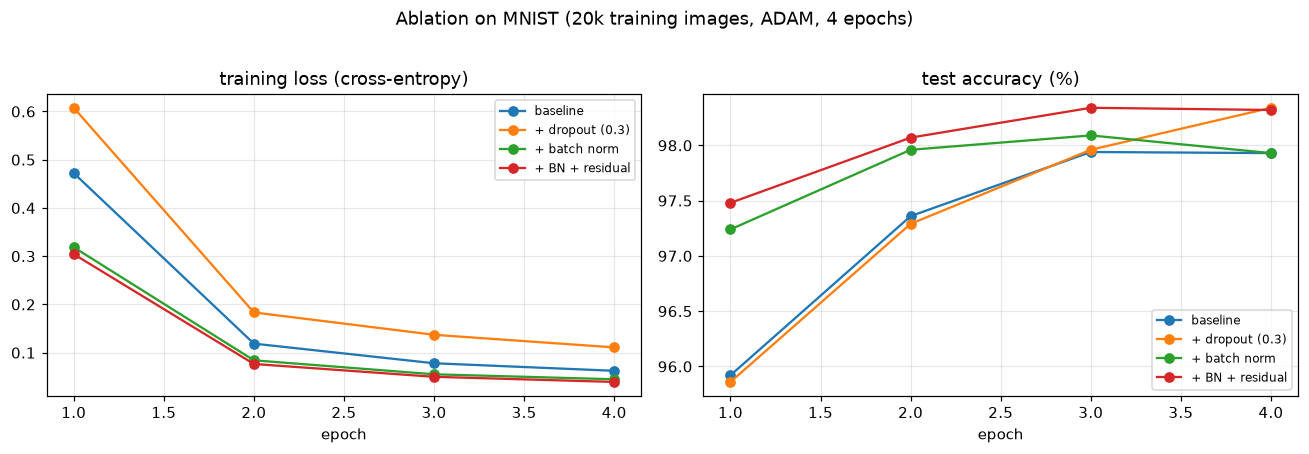

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for name, h in histories.items():
    ep = np.arange(1, len(h["test_acc"]) + 1)
    axes[0].plot(ep, h["train_loss"], "o-", label=name)
    axes[1].plot(ep, 100 * np.array(h["test_acc"]), "o-", label=name)
axes[0].set_title("training loss (cross-entropy)"); axes[0].set_xlabel("epoch")
axes[1].set_title("test accuracy (%)"); axes[1].set_xlabel("epoch")
for ax in axes:
    ax.grid(alpha=0.3); ax.legend(fontsize=8)
plt.suptitle("Ablation on MNIST (20k training images, ADAM, 4 epochs)", y=1.02)
plt.tight_layout()
plt.savefig(FIG / "07_cnn_ablation.png", bbox_inches="tight")
plt.show()

## 4. Softmax outputs, errors, and learned filters

The last layer outputs scores $z_1,\dots,z_{10}$. **Softmax** turns them into probabilities $p_j = e^{z_j}/\sum_k e^{z_k}$, and training minimizes the cross-entropy $-\log p_{\text{true class}}$.

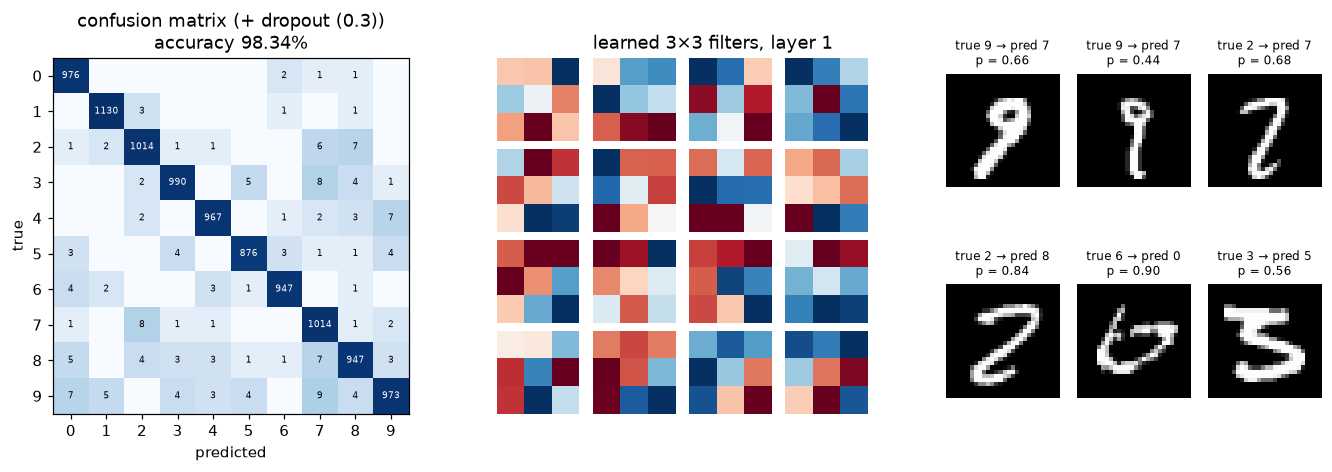

In [8]:
best_name = max(histories, key=lambda n: histories[n]["test_acc"][-1])
best = models[best_name].eval()
test_loader = DataLoader(test_set, batch_size=1000)
preds, labels = [], []
with torch.no_grad():
    for xb, yb in test_loader:
        preds.append(best(xb).argmax(1)); labels.append(yb)
preds, labels = torch.cat(preds).numpy(), torch.cat(labels).numpy()
conf = np.zeros((10, 10), int)
np.add.at(conf, (labels, preds), 1)

wrong = np.flatnonzero(preds != labels)[:6]
fig = plt.figure(figsize=(15, 4.2))
ax = fig.add_subplot(1, 3, 1)
im = ax.imshow(np.log1p(conf), cmap="Blues")
for i in range(10):
    for j in range(10):
        if conf[i, j]:
            ax.text(j, i, conf[i, j], ha="center", va="center", fontsize=6,
                    color="white" if conf[i, j] > 500 else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicted"); ax.set_ylabel("true")
ax.set_title(f"confusion matrix ({best_name})\naccuracy {np.mean(preds == labels):.2%}")

W1 = best.conv1.weight.detach().numpy()[:, 0]
inner = fig.add_gridspec(1, 3)[0, 1].subgridspec(4, 4, wspace=0.1, hspace=0.1)
for k in range(16):
    a = fig.add_subplot(inner[k // 4, k % 4])
    a.imshow(W1[k], cmap="RdBu_r"); a.axis("off")
    if k == 1:
        a.set_title("learned 3×3 filters, layer 1", loc="left")

inner2 = fig.add_gridspec(1, 3)[0, 2].subgridspec(2, 3, wspace=0.15, hspace=0.45)
with torch.no_grad():
    for k, idx in enumerate(wrong):
        p = F.softmax(best(test_set[idx][0][None]), dim=1)[0]
        a = fig.add_subplot(inner2[k // 3, k % 3])
        a.imshow(test_set[idx][0][0], cmap="gray"); a.axis("off")
        a.set_title(f"true {labels[idx]} → pred {preds[idx]}\np = {p[preds[idx]]:.2f}", fontsize=8)
plt.savefig(FIG / "07_cnn_results.png", bbox_inches="tight")
plt.show()

### Takeaways
* A convolution reuses the same small set of weights at every pixel, so a 3×3 layer has 9 weights per channel pair instead of one weight per pixel pair. That weight sharing is why CNNs dominate image tasks.
* Max-pooling halves the resolution and adds some translation invariance.
* In this short training run, batch normalization speeds up optimization. Dropout trades a little training speed for regularization, and its benefit grows with longer training and bigger models.
* The residual connection $x + F(x)$ lets gradients flow through deep networks, which made the 100+ layer ResNets mentioned in the thesis possible.